In [78]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asfandyar250/network")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'network' dataset.
Path to dataset files: /kaggle/input/network


STEP 1 : INSTALL LIBRARIES

In [79]:
!pip install pandas numpy matplotlib seaborn scikit-learn

STEP 2: LOAD DATASET

In [80]:
import pandas as pd
from google.colab import files

# Loaded file name from your upload:
df = pd.read_csv("network_protocol_dataset_100000.csv")

# Check the data:
df.head()

,No.,Time,Source,Destination,Protocol,Length,Info
0,45255,1155.629726,2409:40f4:100b:c1b6:b9fb:3ec3:5675:a236,2a04:4e42:25::760,TCP,86,58090 > 443 [ACK] Seq=1773 Ack=638084 Win=89...
1,4998,243.863452,10.0.2.2,10.0.2.15,TCP,66,5432 > 49544 [ACK] Seq=1 Ack=518 Win=6912 Le...
2,60575,2119.824064,192.168.239.25,13.107.5.93,TLSv1.2,85,Encrypted Alert
3,13300,385.383827,2a04:4e42:25::762,2409:40f4:100b:c1b6:b9fb:3ec3:5675:a236,TLSv1.3,1374,"Application Data, Application Data"
4,2200,40.976175,192.168.56.107,192.168.56.115,TCP,66,"445 > 36503 [SYN, ACK] Seq=0 Ack=1 Win=65535..."


STEP 3:CHECK THE DATASET


In [81]:
df.shape

(100000, 7)

In [82]:
df.columns

Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')

In [83]:
df.dtypes

,0
No.,int64
Time,float64
Source,object
Destination,object
Protocol,object
Length,int64
Info,object


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   No.          100000 non-null  int64  
 1   Time         100000 non-null  float64
 2   Source       100000 non-null  object 
 3   Destination  100000 non-null  object 
 4   Protocol     100000 non-null  object 
 5   Length       100000 non-null  int64  
 6   Info         100000 non-null  object 
dtypes: float64(1), int64(2), object(4)
memory usage: 5.3+ MB


In [85]:
df.describe()

,No.,Time,Length
count,100000.000000,100000.000000,100000.000000
mean,20220.531960,334.897761,189.887790
std,23008.349597,943.000556,371.066867
min,1.000000,0.000000,42.000000
25%,2493.000000,5.277884,54.000000
50%,9322.000000,18.943497,66.000000
75%,37009.250000,200.471034,119.000000
max,117084.000000,6941.356968,6054.000000


STEP 4: CHECK MISSING VALUE

In [86]:
df.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0


STEP 5 : CHECK DUPLICATE RECORDS

In [87]:
df.duplicated().sum()

np.int64(1)

duplicate value detected

In [88]:
df = df.drop_duplicates()


In [89]:
print("dataset shape: ",df.shape)

dataset shape:  (99999, 7)


again check

In [90]:
df.duplicated().sum()

np.int64(0)

STEP 6: UNDERSTAND TARGET VERIABLES(TARGET "PROTOCOL")

In [91]:
df["Protocol"].unique()

array(['TCP', 'TLSv1.2', 'TLSv1.3', 'DCERPC', 'ICMP', 'SMB2',
       'RPC_NETLOGON', 'EPM', 'QUIC', 'DNS', 'VNC', 'SMB', 'STP', 'UDP',
       'ARP', 'SSHv2', 'MySQL', 'HTTP', 'NBNS', 'RESP', 'IPv4', 'BROWSER',
       'ICMPv6', 'Portmap', 'LLMNR', 'MDNS', 'IGMPv3', 'SSDP', 'Rlogin',
       'TELNET', 'NTP', 'RSTAT', 'RMI', 'TLSv1', 'SMTP', 'OCSP', 'YPSERV',
       'RSH', 'FTP', 'MOUNT', 'IRC', 'SSLv2', 'SSHv1', 'HTTP/XML',
       'AJP13', '0x6002', 'PGSQL', 'CDP', 'RPC', 'DHCPv6', 'NFS', 'ENIP',
       'DHCP', 'X11', 'EXEC', 'NBSS', 'HTTP/JSON'], dtype=object)

In [92]:
df["Protocol"].value_counts()

,count
Protocol,
TCP,58141
ICMP,8103
QUIC,6389
DCERPC,5329
RPC_NETLOGON,5262
EPM,2685
SMB2,2552
TLSv1.2,2000
TLSv1.3,1604


STEP 7:VISUALIZE PROTOCOLS

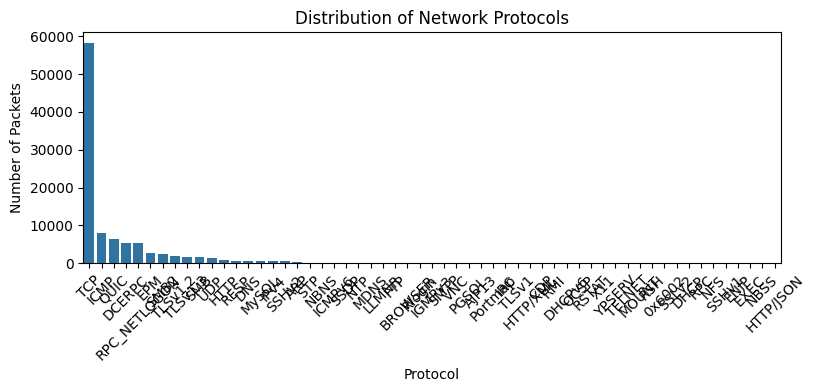

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 3))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")

plt.show()

STEP 8: ANALYZE PACKET LENGTH

In [94]:
df["Length"].describe()

,Length
count,99999.000000
mean,189.889089
std,371.068495
min,42.000000
25%,54.000000
50%,66.000000
75%,119.000000
max,6054.000000


Histogram :

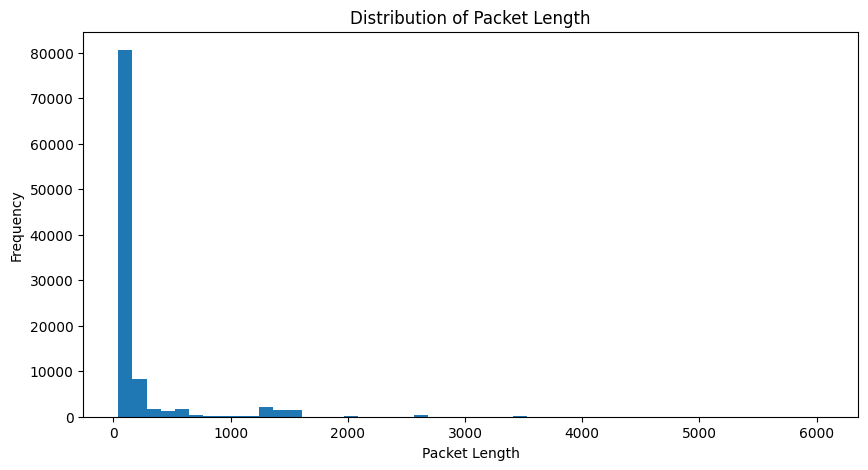

In [95]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()

BOX PLOT :

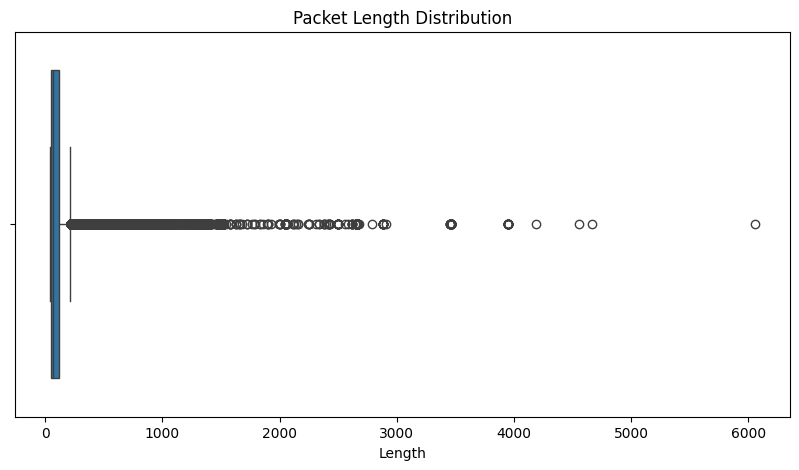

In [96]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")

plt.show()

STEP 9 : CREATE USEFUL FEATURES

In [97]:
df["Time"].head()

,Time
0,1155.629726
1,243.863452
2,2119.824064
3,385.383827
4,40.976175


In [98]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

In [99]:
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

In [100]:
df[["Time", "Hour", "Minute", "Second"]].head()

,Time,Hour,Minute,Second
0,1970-01-01 00:00:00.000001155,0,0,0
1,1970-01-01 00:00:00.000000243,0,0,0
2,1970-01-01 00:00:00.000002119,0,0,0
3,1970-01-01 00:00:00.000000385,0,0,0
4,1970-01-01 00:00:00.000000040,0,0,0


STEP 10: FEATURES WE SHOULD USE
Use:
   length,hour,minute,second.
Target:
   Protocol   

In [101]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]

STEP 11: CHECK X AND Y

In [102]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Length  Hour  Minute  Second
0      86     0       0       0
1      66     0       0       0
2      85     0       0       0
3    1374     0       0       0
4      66     0       0       0

Target:
0        TCP
1        TCP
2    TLSv1.2
3    TLSv1.3
4        TCP
Name: Protocol, dtype: object


In [103]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (99999, 4)
y shape: (99999,)


STEP 12: HANDLE MISSING FEATURES VALUES

In [104]:
print(X.isnull().sum())

Length    0
Hour      0
Minute    0
Second    0
dtype: int64


STEP 13:ENCODE PROTOCOLS

In [105]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [106]:
print(label_encoder.classes_)

['0x6002' 'AJP13' 'ARP' 'BROWSER' 'CDP' 'DCERPC' 'DHCP' 'DHCPv6' 'DNS'
 'ENIP' 'EPM' 'EXEC' 'FTP' 'HTTP' 'HTTP/JSON' 'HTTP/XML' 'ICMP' 'ICMPv6'
 'IGMPv3' 'IPv4' 'IRC' 'LLMNR' 'MDNS' 'MOUNT' 'MySQL' 'NBNS' 'NBSS' 'NFS'
 'NTP' 'OCSP' 'PGSQL' 'Portmap' 'QUIC' 'RESP' 'RMI' 'RPC' 'RPC_NETLOGON'
 'RSH' 'RSTAT' 'Rlogin' 'SMB' 'SMB2' 'SMTP' 'SSDP' 'SSHv1' 'SSHv2' 'SSLv2'
 'STP' 'TCP' 'TELNET' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP' 'VNC' 'X11'
 'YPSERV']


In [107]:
print(y_encoded[:20])

[48 48 51 52 48 48  5 48 48 48 48 48 48 16 48 48 48 48 48 48]


Step 14 — Split the dataset

In [108]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42
)

In [109]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 79999
Testing samples: 20000


Step 15 — Feature scaling

In [110]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)



Step 16 — Model 1: Logistic Regression

In [111]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", accuracy_lr)
print("Accuracy:", accuracy_lr * 100, "%")

Logistic Regression Accuracy: 0.64005
Accuracy: 64.005 %


Step 17 — Classification report

In [112]:
from sklearn.metrics import classification_report
import numpy as np

print(classification_report(
    y_test,
    y_pred_lr,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

      0x6002       0.00      0.00      0.00         0
       AJP13       0.00      0.00      0.00         2
         ARP       0.00      0.00      0.00        57
     BROWSER       0.00      0.00      0.00         5
         CDP       0.00      0.00      0.00         1
      DCERPC       0.00      0.00      0.00      1076
        DHCP       0.00      0.00      0.00         1
      DHCPv6       0.00      0.00      0.00         1
         DNS       0.00      0.00      0.00       112
        ENIP       0.00      0.00      0.00         0
         EPM       0.00      0.00      0.00       541
        EXEC       0.00      0.00      0.00         0
         FTP       0.00      0.00      0.00         4
        HTTP       0.00      0.00      0.00       149
   HTTP/JSON       0.00      0.00      0.00         0
    HTTP/XML       0.00      0.00      0.00         1
        ICMP       0.97      0.99      0.98      1638
      ICMPv6       0.00    

Step 18 — Confusion Matrix

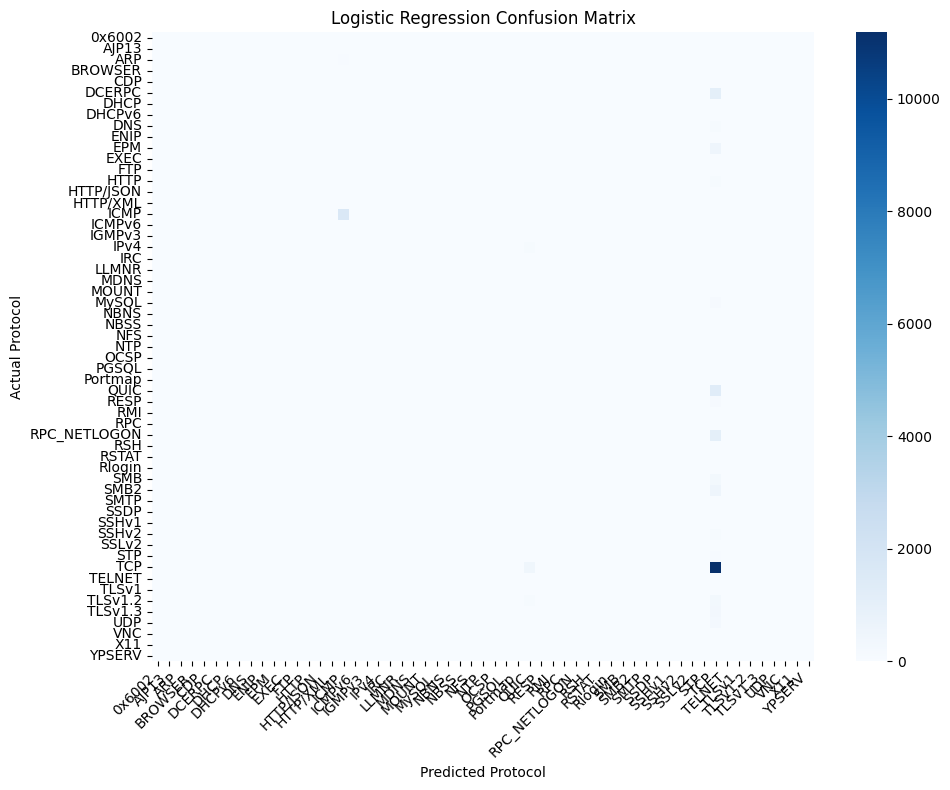

In [113]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

labels = np.arange(len(label_encoder.classes_))
cm = confusion_matrix(y_test, y_pred_lr, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=len(labels) <= 15,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 19 — Model 2: KNN

In [114]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("KNN Accuracy:", accuracy_knn * 100, "%")

KNN Accuracy: 93.67 %


Step 20 — Model 3: Decision Tree

In [115]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 92.235 %


Step 21 — Visualize the Decision Tree

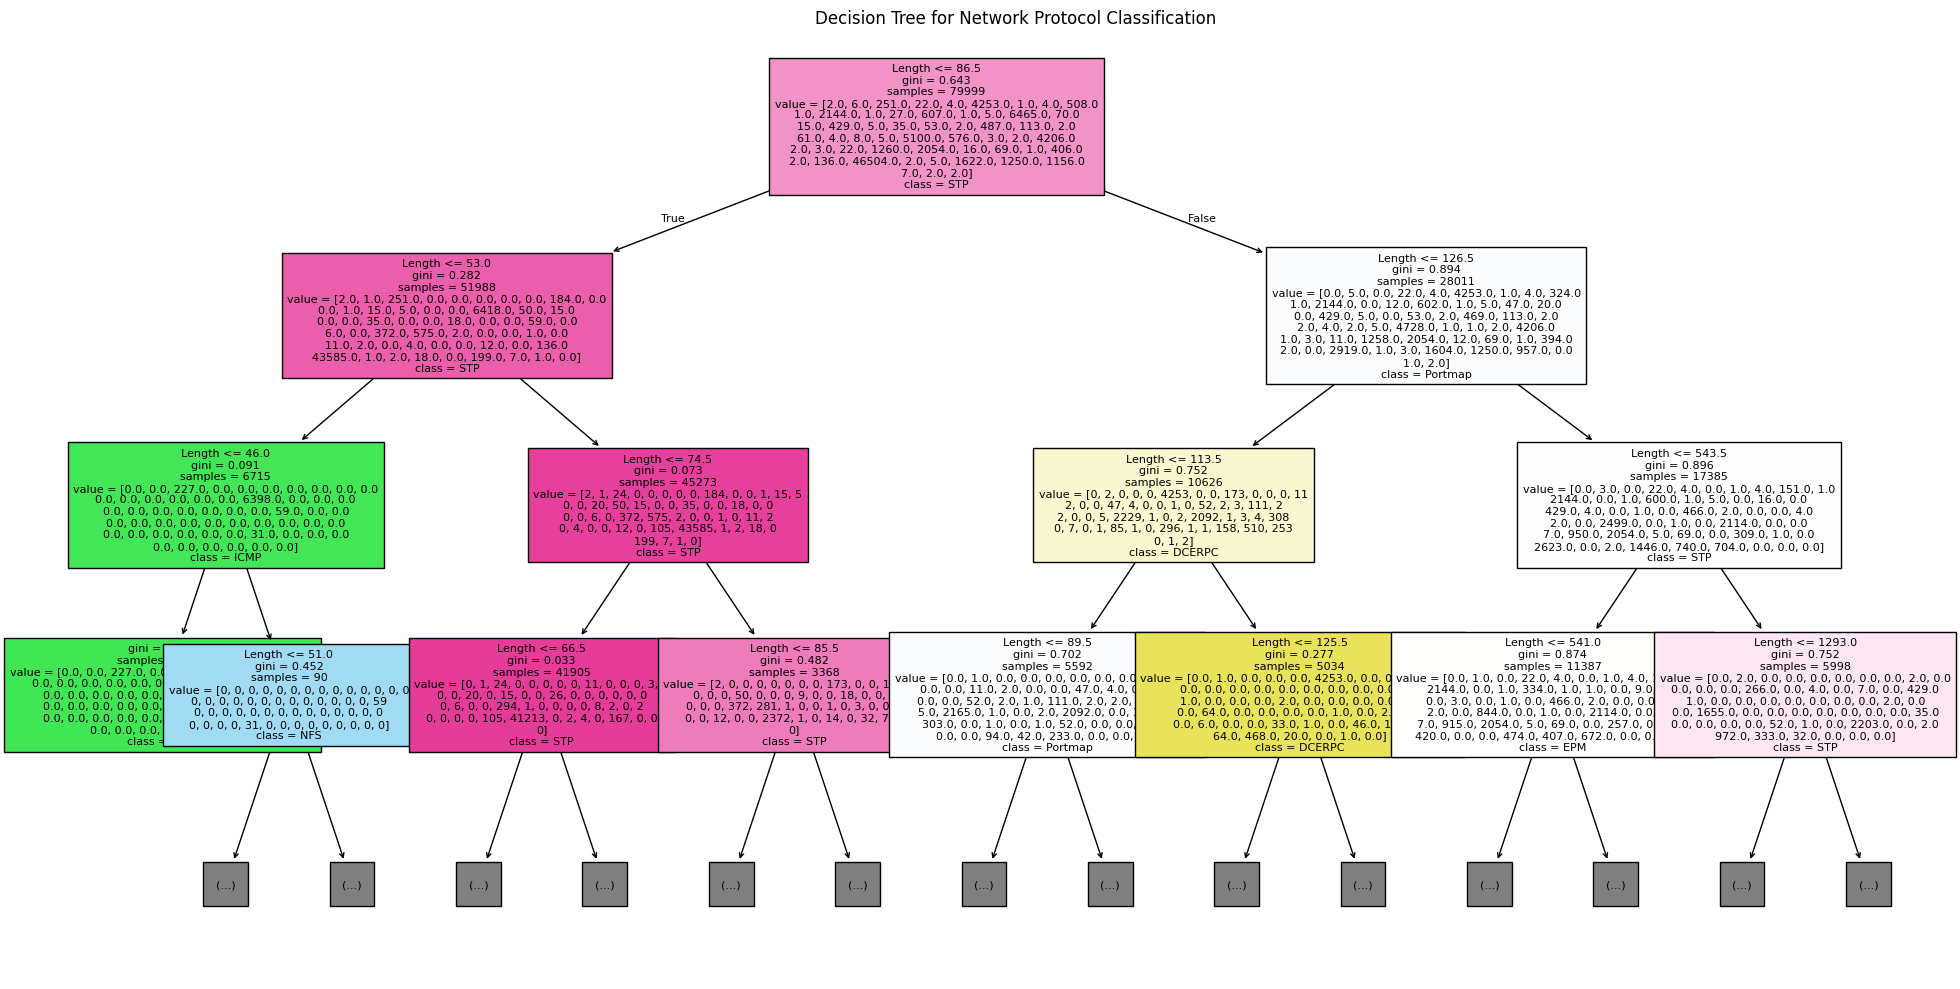

In [116]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Network Protocol Classification")
plt.tight_layout()
plt.show()

Step 22 — Model 4: Random Forest

In [117]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf * 100, "%")

Random Forest Accuracy: 93.93 %


Step 23 — Compare all models

In [118]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100
display(results.sort_values("Accuracy", ascending=False))

,Model,Accuracy,Accuracy (%)
3,Random Forest,0.93930,93.930
1,KNN,0.93670,93.670
2,Decision Tree,0.92235,92.235
0,Logistic Regression,0.64005,64.005


Step 24 — Plot model comparison

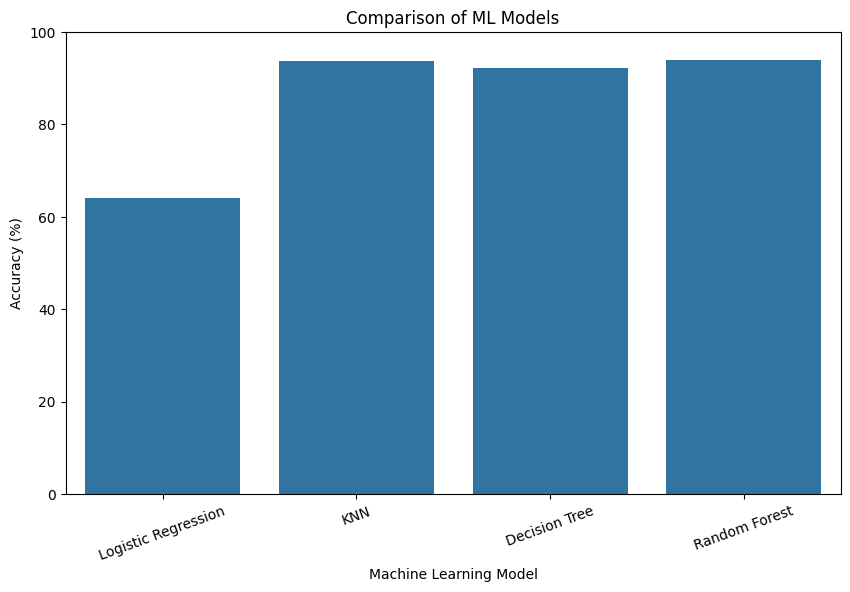

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=results, x="Model", y="Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.title("Comparison of ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.show()

Step 25 — Find the best model

In [120]:
best_model = results.loc[results["Accuracy"].idxmax()]

print("Best Model:")
print(best_model)

Best Model:
Model           Random Forest
Accuracy               0.9393
Accuracy (%)            93.93
Name: 3, dtype: object


Step 26 — Feature importance

,Feature,Importance
0,Length,1.0
1,Hour,0.0
2,Minute,0.0
3,Second,0.0


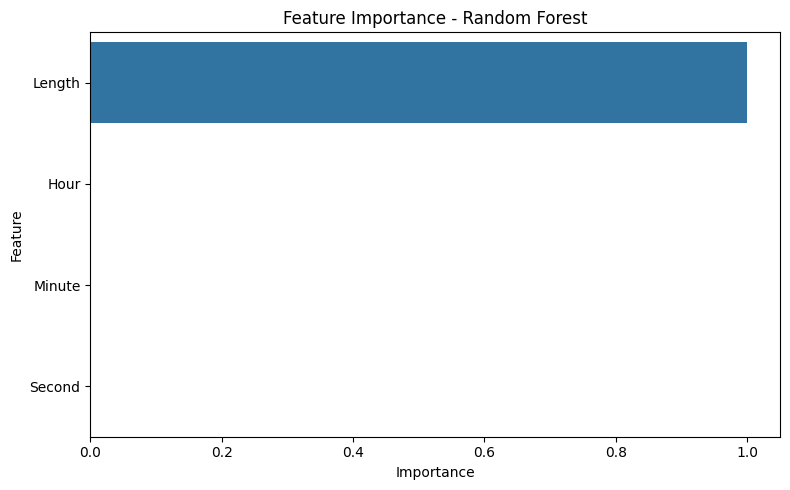

In [121]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

Step 27 — Detailed evaluation of Random Forest

              precision    recall  f1-score   support

      0x6002       0.00      0.00      0.00         0
       AJP13       0.00      0.00      0.00         2
         ARP       0.00      0.00      0.00        57
     BROWSER       0.31      1.00      0.48         5
         CDP       0.20      1.00      0.33         1
      DCERPC       0.98      1.00      0.99      1076
        DHCP       0.00      0.00      0.00         1
      DHCPv6       0.00      0.00      0.00         1
         DNS       0.69      0.48      0.57       112
        ENIP       0.00      0.00      0.00         0
         EPM       0.92      1.00      0.96       541
        EXEC       0.00      0.00      0.00         0
         FTP       0.00      0.00      0.00         4
        HTTP       0.65      0.67      0.66       149
   HTTP/JSON       0.00      0.00      0.00         0
    HTTP/XML       0.00      0.00      0.00         1
        ICMP       0.97      0.99      0.98      1638
      ICMPv6       0.67    

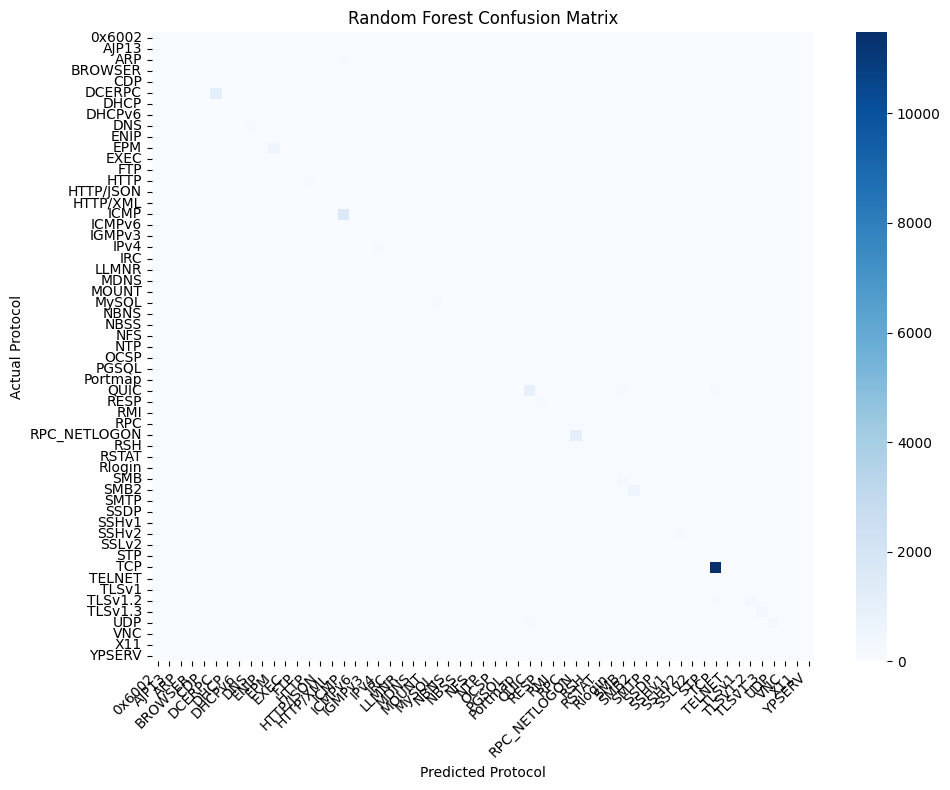

In [122]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

labels = np.arange(len(label_encoder.classes_))

print(classification_report(
    y_test,
    y_pred_rf,
    labels=labels,
    target_names=label_encoder.classes_,
    zero_division=0
))

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_rf,
    annot=len(labels) <= 15,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 28 — Predict a new packet

In [123]:
new_packet = pd.DataFrame({"Length": [64]})

new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})

new_packet = new_packet[X_train.columns]

prediction = rf_model.predict(new_packet)
predicted_protocol = label_encoder.inverse_transform(prediction)

print("Predicted Protocol:", predicted_protocol[0])

Predicted Protocol: LLMNR
